# 01 — Measured vs. analytic grinding cost (RQ1, H1, H1b)

For every grind config of the campaign: is the measured mean number of tries equal to the analytic
1/p, and is the whole distribution geometric with that *analytic* p (nothing fitted)?

Tests per config
- **mean ratio** with a 95 % CI (normal approximation; n ≥ 2·10⁴ samples).
- **randomized PIT**: under H0, U = F(T−1) + V·(F(T) − F(T−1)) is exactly U(0,1) for a discrete T.
  KS (shape in the bulk) and Anderson–Darling (weights the tails) on U. Holm correction across configs.

Also: the true compressions per attempt of each grind layout (H1b) and whether any config window was
thermally throttled.

In [1]:
import sys; sys.path.insert(0, '.')
import zlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import common as C
OUT = C.out_dir('01_validate')
s = C.summary()
print(f"run {C.RUN_ID}: {len(s)} configs, {int(s.n.sum()):,} grind samples, all reference-verified: {bool(s.verified_all.all())}")

run 196e7e91e907: 37 configs, 11,160,000 grind samples, all reference-verified: True


## Mean vs. analytic, distribution tests

In [2]:
rows = []
for cid, r in s.iterrows():
    t = C.tries(cid)
    g = C.geometric_tests(t, r.expected_tries, seed=zlib.crc32(cid.encode()))
    rows.append({'config_id': cid, 'grind': C.KIND_LABEL[r.kind], 'n': int(r.n), 'E_analytic': r.expected_tries,
                 'mean': r.mean_tries, 'ratio': r.ratio, 'ci95_rel': r.ci95_rel, 'z': r.z_score,
                 'var_ratio': t.var(ddof=1) / (r.expected_tries**2 - r.expected_tries), **g})
v = pd.DataFrame(rows).set_index('config_id')
v['ks_p_holm'] = C.holm(v.ks_p)
v['ad_reject_5pct'] = v.ad_stat > C.AD_CRIT_5PCT
chi2 = float((v.z**2).sum()); dof = len(v)
print(f"sum z^2 = {chi2:.1f} on {dof} dof -> p = {stats.chi2.sf(chi2, dof):.3f}")
print(f"|z| > 1.96: {int((v.z.abs() > 1.96).sum())} (expected {0.05*dof:.1f});  max |ratio-1| = {100*(v.ratio-1).abs().max():.2f} %")
print(f"KS rejections after Holm (5 %): {int((v.ks_p_holm < 0.05).sum())};  AD > 5 % critical value: {int(v.ad_reject_5pct.sum())} (expected {0.05*dof:.1f})")
print(f"all |ratio-1| < 2 % (DoD): {bool(((v.ratio-1).abs() < 0.02).all())}")
C.to_markdown(v.round(5), OUT / 'validation.md')
v.to_csv(OUT / 'validation.csv')
v[['grind', 'n', 'E_analytic', 'ratio', 'ci95_rel', 'z', 'var_ratio', 'ks_p', 'ks_p_holm', 'ad_stat']]

sum z^2 = 39.6 on 37 dof -> p = 0.355
|z| > 1.96: 2 (expected 1.9);  max |ratio-1| = 1.66 %
KS rejections after Holm (5 %): 0;  AD > 5 % critical value: 2 (expected 1.9)
all |ratio-1| < 2 % (DoD): True


,grind,n,E_analytic,ratio,ci95_rel,z,var_ratio,ks_p,ks_p_holm,ad_stat
config_id,,,,,,,,,,
wots-w16-S240-z0,WOTS+C,1000000,6.567584e+01,0.999637,0.001942,-0.366088,0.995918,0.734700,1.0,0.761651
wots-w256-S2040-z0,WOTS+C,1000000,7.480070e+02,0.999210,0.001957,-0.791290,0.996744,0.931919,1.0,0.435975
wots-w16-S304-z0,WOTS+C,1000000,1.335259e+03,1.000316,0.001959,0.316513,1.000069,0.281339,1.0,0.991172
wots-w256-S2440-z0,WOTS+C,1000000,1.824106e+03,0.998952,0.001960,-1.048228,0.998157,0.501898,1.0,0.616194
pors-k10-a12-h27-m93,PORS+FP,100000,2.976269e+03,0.995492,0.006166,-1.433134,0.981046,0.736630,1.0,0.811482
pors-k9-a15-h32-m109,PORS+FP,100000,3.454038e+03,1.000066,0.006217,0.020773,1.006428,0.729295,1.0,0.727223
pors-k9-a13-h48-m91,PORS+FP,100000,3.820912e+03,1.004268,0.006179,1.353709,1.002714,0.679622,1.0,1.239580
fors_ctr-k11-a14,FORS+C (ctr-grind),200000,1.638400e+04,1.001803,0.004381,0.806758,1.002714,0.812823,1.0,0.343510
fors_ctr-k10-a14,FORS+C (ctr-grind),200000,1.638400e+04,1.000229,0.004383,0.102281,1.000722,0.644942,1.0,0.574714


`var_ratio` compares the sample variance with the geometric variance (1−p)/p². Values near 1 mean the
spread, not only the mean, matches the model.

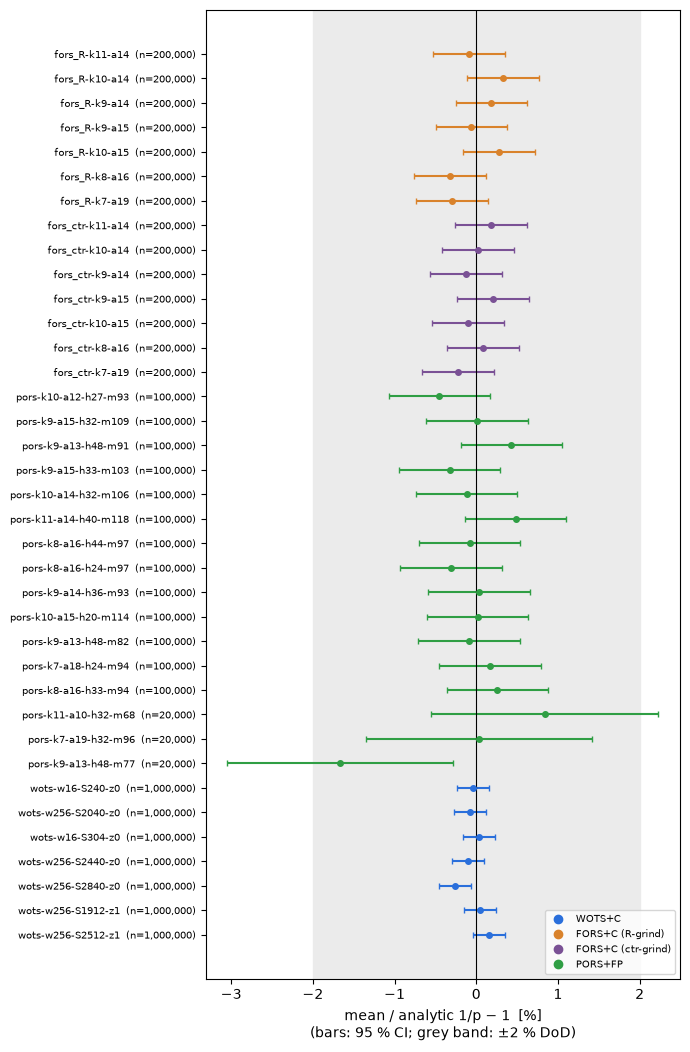

In [3]:
order = v.sort_values(['grind', 'E_analytic']).index
fig, ax = plt.subplots(figsize=(7, 0.26 * len(order) + 1))
y = np.arange(len(order))
colors = {k: c for k, c in zip(C.KIND_LABEL.values(), ['#2a6fdb', '#d9822b', '#7a5195', '#2f9e44'])}
for i, cid in enumerate(order):
    r = v.loc[cid]
    ax.errorbar((r.ratio - 1) * 100, i, xerr=r.ci95_rel * 100, fmt='o', ms=4, color=colors[r.grind], capsize=2)
ax.axvline(0, color='k', lw=0.8); ax.axvspan(-2, 2, color='0.92', zorder=0)
ax.set_yticks(y, [f"{c}  (n={v.loc[c,'n']:,})" for c in order], fontsize=7)
ax.set_xlabel('mean / analytic 1/p − 1  [%]\n(bars: 95 % CI; grey band: ±2 % DoD)')
for g, c in colors.items(): ax.plot([], [], 'o', color=c, label=g)
ax.legend(fontsize=7, loc='lower right'); ax.invert_yaxis(); fig.tight_layout()
fig.savefig(OUT / 'forest_mean_ratio.png', dpi=160); fig.savefig(OUT / 'forest_mean_ratio.svg')

## PIT histograms (uniform under H0) for the largest config of each grind type

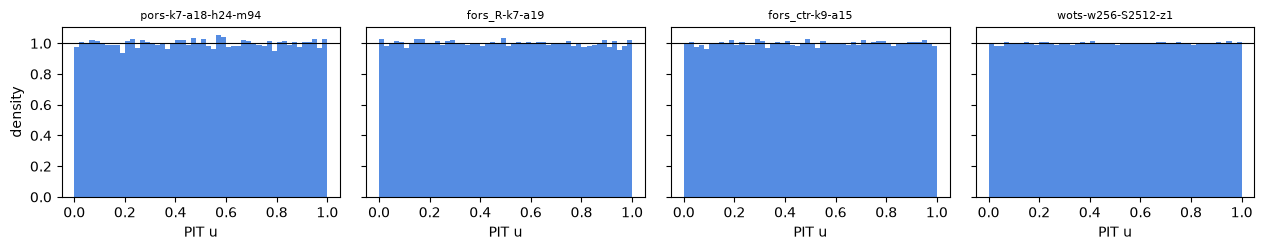

In [4]:
pick = s.reset_index().sort_values('n').groupby('kind').tail(1).config_id
fig, axs = plt.subplots(1, len(pick), figsize=(3.2 * len(pick), 2.6), sharey=True)
rng = np.random.default_rng(0)
for ax, cid in zip(axs, pick):
    u = C.geometric_pit(C.tries(cid), 1 / s.loc[cid, 'expected_tries'], rng)
    ax.hist(u, bins=50, density=True, color='#2a6fdb', alpha=0.8); ax.axhline(1, color='k', lw=0.8)
    ax.set_title(cid, fontsize=8); ax.set_xlabel('PIT u')
axs[0].set_ylabel('density'); fig.tight_layout(); fig.savefig(OUT / 'pit_hist.png', dpi=160)

## H1b — compressions per attempt and grind throughput per layout

The cost model (`costs.sage`) charges every FORS+C / PORS+FP attempt 4 compressions (C_Hmsg + C_PRFmsg).
Counting through the FIPS 205 SHA-2 instantiation (`ref.fors_c.count_compressions`) gives the real
per-attempt cost. The GPU throughput columns are measured; `efficiency` = useful compressions/s ÷ E0 raw rate.

In [5]:
from ref import fors_c
from runner.configs import COMPRESSIONS
m = C.measured_rates()
raw = m['gpu_raw_sustained']
lay = pd.DataFrame({
    'grind': [C.KIND_LABEL[k] for k in ('wots', 'R', 'ctr', 'pors')],
    'model_comp_per_attempt': [1, 4, 4, 4],
    'counted_comp_per_attempt': [1, fors_c.count_compressions('R'), fors_c.count_compressions('ctr'),
                                 fors_c.count_compressions('R', pors=True)],
    'runner_constant': [COMPRESSIONS[k] for k in ('wots', 'R', 'ctr', 'pors')],
}, index=['wots', 'R', 'ctr', 'pors'])
g = s.groupby('kind')
lay['gpu_attempts_per_s_median'] = g.attempts_per_s.median()
lay['gpu_useful_comp_per_s_median'] = g.comp_per_s.median()
lay['efficiency_vs_E0'] = lay.gpu_useful_comp_per_s_median / raw
lay['model_underestimate_x'] = lay.counted_comp_per_attempt / lay.model_comp_per_attempt
assert (lay.counted_comp_per_attempt == lay.runner_constant).all()
print(f"E0 sustained raw: {raw/1e9:.3f} Gcomp/s;  ctr-grind attempts/s ÷ R-grind attempts/s = "
      f"{lay.loc['ctr','gpu_attempts_per_s_median']/lay.loc['R','gpu_attempts_per_s_median']:.2f}x")
C.to_markdown(lay, OUT / 'layout_costs.md'); lay

E0 sustained raw: 2.151 Gcomp/s;  ctr-grind attempts/s ÷ R-grind attempts/s = 2.08x


,grind,model_comp_per_attempt,counted_comp_per_attempt,runner_constant,gpu_attempts_per_s_median,gpu_useful_comp_per_s_median,efficiency_vs_E0,model_underestimate_x
wots,WOTS+C,1,1,1,1.346819e+09,1.346819e+09,0.626023,1.00
R,FORS+C (R-grind),4,6,6,3.487294e+08,2.092376e+09,0.972570,1.50
ctr,FORS+C (ctr-grind),4,3,3,7.251378e+08,2.175413e+09,1.011167,0.75
pors,PORS+FP,4,7,7,1.809075e+08,1.266352e+09,0.588621,1.75


Reading: WOTS+C and PORS+FP run well below the raw E0 rate (per-attempt digit extraction / Octopus
set-size work and small grinds), FORS+C runs near it. The ctr-grind layout costs half the compressions of
R-grinding and needs a 4-byte counter in the signature; on the GPU that is ≈2× more attempts per second.

## E6 — power, clocks and throttling inside each config's kernel window

               samples     mean_W     mean_MHz
event_reasons                                 
0                  408  32.273750  2335.588235
1                 3811   2.450407   243.125164
4                71111  44.855148  1978.604646
36                 344  17.921744  2155.203488
busy samples (> 30 W): 71,322, flagged throttled: 0.00014
configs with < 5 power samples (window < 0.5 s): 1
busy-sample throttle fraction, max over configs: 0.1163 (raw flag incl. idle transitions: 0.3571)
mean board power 41.2 W, SM clock 1974 MHz, max temp 80 °C


,seconds,samples,mean_W,mean_sm_MHz,max_temp_C,throttled_frac,busy_throttled_frac
config_id,,,,,,,
fors_ctr-k9-a14,4.750808,43,43.733256,2217.558140,72,0.116279,0.116279
fors_R-k8-a16,38.053721,344,44.012820,2080.552326,77,0.014535,0.014793
wots-w256-S2040-z0,1.199762,10,11.233000,864.000000,65,0.000000,0.000000
wots-w16-S304-z0,1.557590,14,22.402143,1579.285714,67,0.357143,0.000000
pors-k10-a12-h27-m93,2.059546,19,33.362632,1687.894737,68,0.000000,0.000000
wots-w256-S2440-z0,1.779001,16,26.602500,1562.812500,68,0.250000,0.000000
fors_ctr-k11-a14,4.847356,43,39.545349,1952.441860,71,0.000000,0.000000
pors-k9-a15-h32-m109,2.227138,20,42.152000,2154.750000,69,0.100000,0.000000


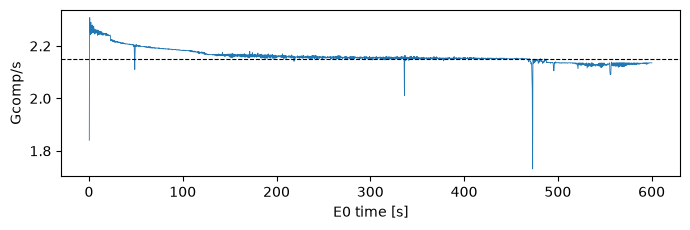

In [6]:
pw = C.power()
BUSY_W = 30  # the kernels hold the 45 W cap; lower readings are launch gaps / P-state transitions
print(pw.groupby('event_reasons').agg(samples=('power_w', 'size'), mean_W=('power_w', 'mean'), mean_MHz=('sm_mhz', 'mean')))
busy = pw[pw.power_w > BUSY_W]
print(f"busy samples (> {BUSY_W} W): {len(busy):,}, flagged throttled: {busy.throttled.mean():.5f}")
rows = []
for cid, r in s.iterrows():
    w = C.window(pw, r.start, r.end)
    rows.append({'config_id': cid, 'seconds': (r.end - r.start).total_seconds(), 'samples': len(w),
                 'mean_W': w.power_w.mean(), 'mean_sm_MHz': w.sm_mhz.mean(), 'max_temp_C': w.temp_c.max(),
                 'throttled_frac': w.throttled.mean() if len(w) else np.nan,
                 'busy_throttled_frac': w.throttled[w.power_w > BUSY_W].mean() if (w.power_w > BUSY_W).any() else np.nan})
th = pd.DataFrame(rows).set_index('config_id')
short = th.samples < 5
print(f"configs with < 5 power samples (window < 0.5 s): {int(short.sum())}")
print(f"busy-sample throttle fraction, max over configs: {th.busy_throttled_frac.max():.4f} "
      f"(raw flag incl. idle transitions: {th.throttled_frac[~short].max():.4f})")
print(f"mean board power {th.mean_W[~short].mean():.1f} W, SM clock {th.mean_sm_MHz[~short].mean():.0f} MHz, max temp {th.max_temp_C.max():.0f} °C")
C.to_markdown(th.round(3), OUT / 'power_windows.md')
e0 = pd.read_parquet(C.run_dir() / 'e0.parquet')
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.plot(e0.t_s, e0.comp_per_s / 1e9, lw=0.6); ax.set_xlabel('E0 time [s]'); ax.set_ylabel('Gcomp/s')
ax.axhline(C.e0()['median_last_2_3'] / 1e9, color='k', lw=0.8, ls='--'); fig.tight_layout()
fig.savefig(OUT / 'e0_trace.png', dpi=160)
th.sort_values('busy_throttled_frac', ascending=False).head(8)

Event reason 0x4 (SW power cap) is the intended steady state at 45 W TGP. 0x20 (SW thermal) only appears
together with 0x4 in low-power P3/P5/P8 states between launches (≈18 W), not under load. So no kernel
window needs discarding; throughput numbers are sustained-at-cap figures.